This dataset contains a list of video games with sales greater than 100,000 copies. It was scrape from vgchartz.com 

Fields include

Rank - Ranking of overall sales

Name - The games name

Platform - Platform of the games release (i.e. PC,PS4, etc.)

Year - Year of the game's release

Genre - Genre of the game

Publisher - Publisher of the game

NA_Sales - Sales in North America (in millions)

EU_Sales - Sales in Europe (in millions)

JP_Sales - Sales in Japan (in millions)

Other_Sales - Sales in the rest of the world (in millions)

Global_Sales - Total worldwide sales.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

In [2]:
df = pd.read_csv('../DataSets/vgsales.csv')

# Data 👇

Top Selling Games:

What are the top-selling games based on global sales revenue?

What is the total global sales revenue across all years?

In [3]:
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [4]:
df.dtypes

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

In [5]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [6]:
df = df.drop('Rank',axis=1)

In [7]:
df.Year.fillna(0,inplace=True)
df.Year = df.Year.astype('int64')
df.Publisher.fillna('Unknown',inplace=True)

In [8]:
df.Name.unique()

array(['Wii Sports', 'Super Mario Bros.', 'Mario Kart Wii', ...,
       'Plushees', 'Woody Woodpecker in Crazy Castle 5', 'Know How 2'],
      dtype=object)

In [9]:
df.Name.nunique()

11493

## Top Selling Games:

### What are the top-selling games based on global sales revenue?

In [10]:
GSR = df.nlargest(5,'Global_Sales')
TSG = GSR[['Name','Global_Sales']]
TSG

,Name,Global_Sales
0,Wii Sports,82.74
1,Super Mario Bros.,40.24
2,Mario Kart Wii,35.82
3,Wii Sports Resort,33.00
4,Pokemon Red/Pokemon Blue,31.37


### What is the total global sales revenue across all years?

In [11]:
df.Year.unique()

array([2006, 1985, 2008, 2009, 1996, 1989, 1984, 2005, 1999, 2007, 2010,
       2013, 2004, 1990, 1988, 2002, 2001, 2011, 1998, 2015, 2012, 2014,
       1992, 1997, 1993, 1994, 1982, 2003, 1986, 2000,    0, 1995, 2016,
       1991, 1981, 1987, 1980, 1983, 2020, 2017], dtype=int64)

In [12]:
df.Global_Sales.sum()

8920.44

Platform Performance:

Which platform has the highest total global sales revenue?

Are there any platforms that consistently produce top-selling games over time?

How does the distribution of global sales revenue vary across different platforms?

## Platform Performance:

In [13]:
df.Platform.unique()

array(['Wii', 'NES', 'GB', 'DS', 'X360', 'PS3', 'PS2', 'SNES', 'GBA',
       '3DS', 'PS4', 'N64', 'PS', 'XB', 'PC', '2600', 'PSP', 'XOne', 'GC',
       'WiiU', 'GEN', 'DC', 'PSV', 'SAT', 'SCD', 'WS', 'NG', 'TG16',
       '3DO', 'GG', 'PCFX'], dtype=object)

### Which platform has the highest total global sales revenue?

In [14]:
HPR = df.groupby('Platform')['Global_Sales'].sum()
HPR.nlargest(5)

Platform
PS2     1255.64
X360     979.96
PS3      957.84
Wii      926.71
DS       822.49
Name: Global_Sales, dtype: float64

### Are there any platforms that consistently produce top-selling games over time? 

In [15]:
GOT = df.groupby('Platform')['Global_Sales'].mean().nlargest(5)
GOT

Platform
GB      2.606633
NES     2.561939
GEN     1.050370
SNES    0.837029
PS4     0.827679
Name: Global_Sales, dtype: float64

### How does the distribution of global sales revenue vary across different platforms? 

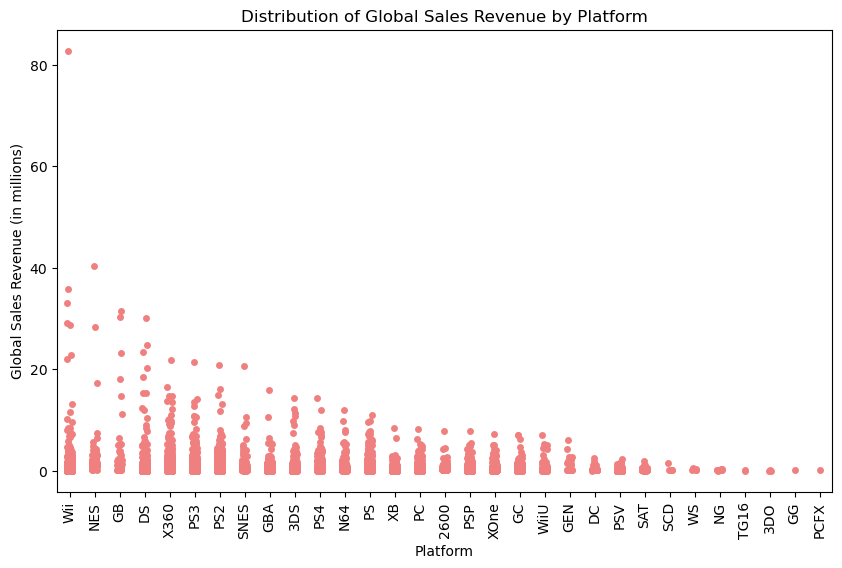

In [16]:
plt.figure(figsize=(10, 6))
sb.stripplot(x = df.Platform,y = df.Global_Sales,color='lightcoral')
plt.title('Distribution of Global Sales Revenue by Platform')
plt.xlabel('Platform')
plt.ylabel('Global Sales Revenue (in millions)')
plt.xticks(rotation=90)
plt.show()

Genre Analysis:

What are the most popular genres in terms of global sales revenue?

Are certain genres more successful on specific platforms or in particular regions?

Can we identify any emerging trends or shifts in genre preferences over time?

## Genre Analysis:

In [17]:
df.Genre.unique()

array(['Sports', 'Platform', 'Racing', 'Role-Playing', 'Puzzle', 'Misc',
       'Shooter', 'Simulation', 'Action', 'Fighting', 'Adventure',
       'Strategy'], dtype=object)

### What are the most popular genres in terms of global sales revenue?

In [4]:
PG = df.groupby('Genre')['Global_Sales'].sum()
GP =PG.nlargest(5)
GP

Genre
Action          1751.18
Sports          1330.93
Shooter         1037.37
Role-Playing     927.37
Platform         831.37
Name: Global_Sales, dtype: float64

### Are certain genres more successful on specific platforms or in particular regions?

In [19]:
PR = pd.pivot_table(data=df,index='Genre',columns='Platform',values='Global_Sales',aggfunc='sum',margins=True).nlargest(10,'All')
PR

Platform,2600,3DO,3DS,DC,DS,GB,GBA,GC,GEN,GG,...,SCD,SNES,TG16,WS,Wii,WiiU,X360,XB,XOne,All
Genre,,,,,,,,,,,,,,,,,,,,,
All,97.08,0.10,247.46,15.97,822.49,255.45,318.50,199.36,28.36,0.04,...,1.87,200.05,0.16,1.42,926.71,81.86,979.96,258.26,141.06,8920.44
Action,29.34,NaN,57.02,1.26,115.56,7.92,55.76,37.84,2.74,NaN,...,NaN,10.08,NaN,NaN,118.58,19.35,242.67,49.28,33.79,1751.18
Sports,3.43,NaN,6.20,3.66,31.83,9.05,16.41,25.49,3.20,NaN,...,NaN,17.87,NaN,NaN,292.06,3.32,139.12,54.27,23.97,1330.93
Shooter,26.48,NaN,1.29,0.33,8.20,1.20,3.60,13.63,0.13,NaN,...,NaN,6.07,0.02,NaN,28.77,6.17,278.55,63.55,51.61,1037.37
Role-Playing,NaN,NaN,75.74,0.68,126.85,88.24,64.21,13.15,0.27,NaN,...,0.06,36.43,NaN,1.22,14.06,2.47,71.98,13.51,9.48,927.37
Platform,13.27,NaN,32.23,2.54,77.45,54.91,78.30,28.66,15.45,0.04,...,1.50,65.65,NaN,NaN,90.74,21.24,11.39,9.66,0.81,831.37
Misc,3.58,NaN,10.48,NaN,137.76,13.35,36.25,16.73,0.03,NaN,...,0.10,5.02,NaN,NaN,221.06,12.23,91.96,9.58,6.86,809.96
Racing,2.91,NaN,14.49,2.65,38.64,4.55,18.80,21.89,0.26,NaN,...,0.07,13.49,NaN,NaN,61.28,7.77,65.99,31.49,8.80,732.04
Fighting,1.24,NaN,10.46,1.83,7.20,NaN,4.21,18.43,5.90,NaN,...,NaN,26.95,NaN,NaN,23.86,6.36,37.64,13.55,2.31,448.91


### Can we identify any emerging trends or shifts in genre preferences over time?

In [5]:
selected_genres = GP.index
TGT = df.loc[(df['Year'] != 0) & (df['Genre']) & (df['Global_Sales'])]
GT = TGT.groupby(['Year','Genre'])['Global_Sales'].sum().reset_index()

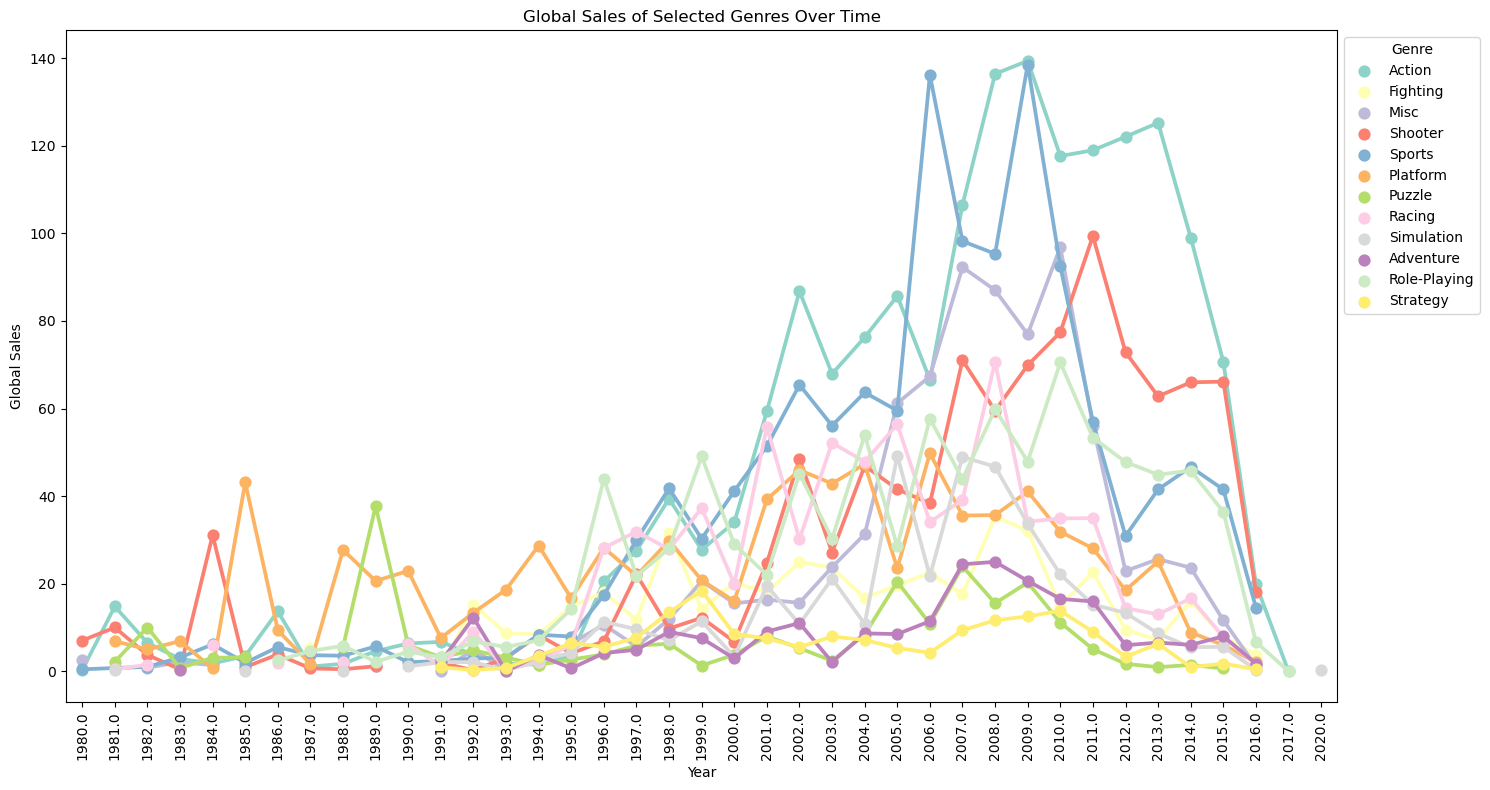

In [10]:
plt.figure(figsize=(15,8 ))
sb.pointplot(x=GT.Year,y=GT.Global_Sales,hue=GT.Genre,palette='Set3')
plt.title('Global Sales of Selected Genres Over Time')
plt.xlabel('Year')
plt.ylabel('Global Sales')
plt.legend(title='Genre',bbox_to_anchor=(1.00,1))
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Publisher Performance:

Which publisher has the highest total global sales revenue according to genre?

How does the performance of publishers vary in different regions?

## Publisher Performance:

### Which publisher has the highest total global sales revenue according to genre?

In [22]:
PG = df.groupby(['Genre','Publisher'])[['Global_Sales']].sum().reset_index()
P = PG.nlargest(10,'Global_Sales')

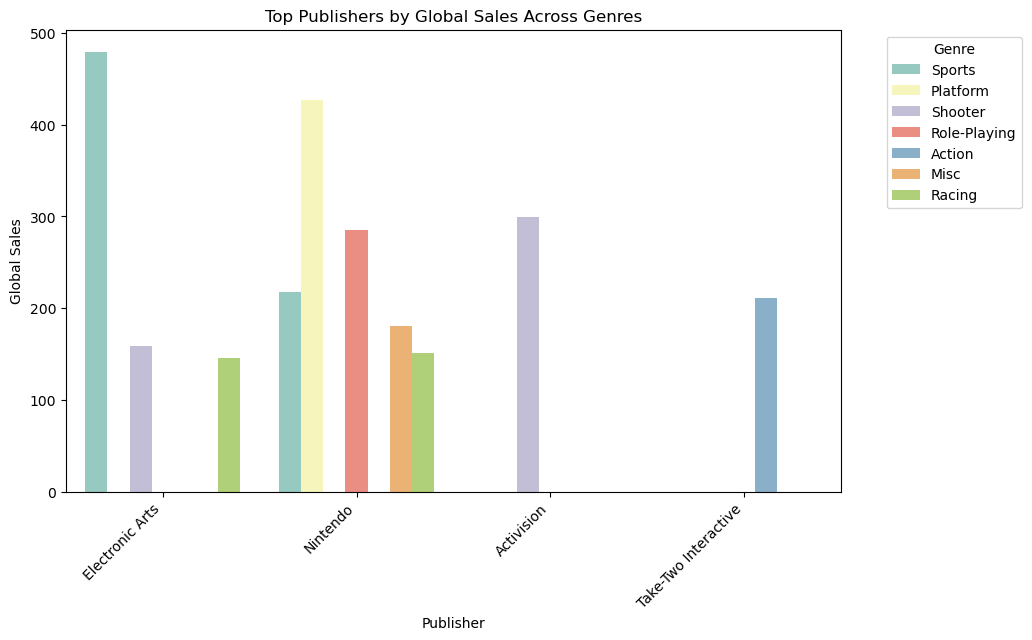

In [38]:
plt.figure(figsize=(10, 6))
sb.barplot(x=P.Publisher,y=P.Global_Sales,hue=P.Genre,palette='Set3')
plt.title('Top Publishers by Global Sales Across Genres')
plt.xlabel('Publisher')
plt.ylabel('Global Sales')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Genre',bbox_to_anchor=(1.05,1))
plt.show()

### How does the performance of publishers vary in different regions?

In [24]:
POP = df.groupby('Publisher')[['NA_Sales','EU_Sales','JP_Sales','Other_Sales','Global_Sales']].sum()
NA = POP.nlargest(5,'NA_Sales')
EU = POP.nlargest(5,'EU_Sales')
JP = POP.nlargest(5,'JP_Sales')
Other = POP.nlargest(5,'Other_Sales')
Global = POP.nlargest(5,'Global_Sales')

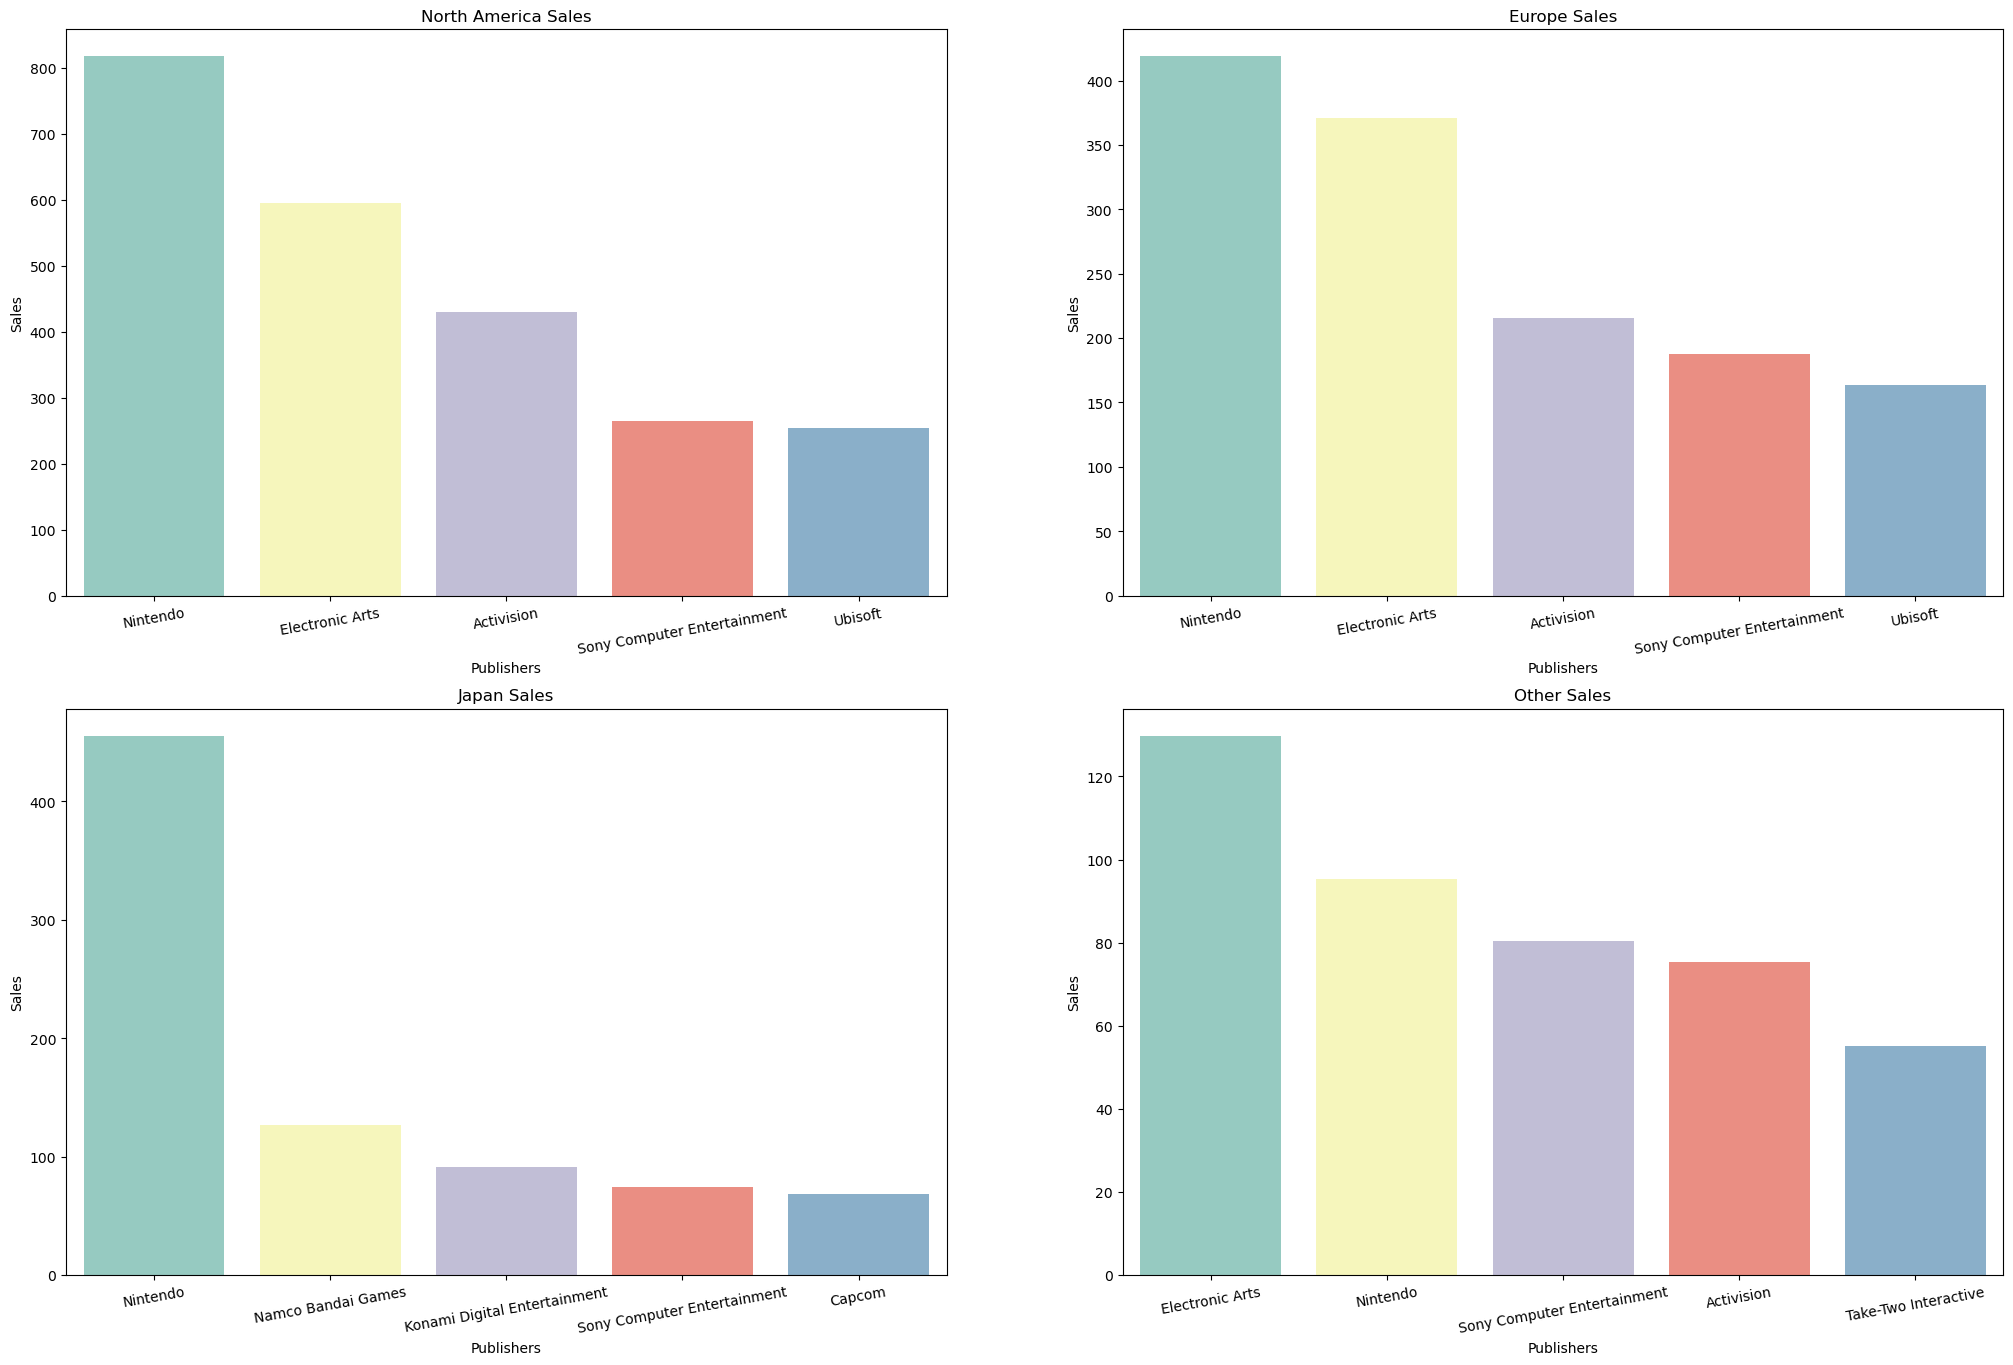

In [25]:
fig = plt.figure(figsize = (25,25))

ax1 = fig.add_subplot(321)
sb.barplot(x = NA.index,y =NA.NA_Sales, palette= 'Set3')
ax1.set_title('North America Sales')
ax1.set_ylabel('Sales')
ax1.set_xlabel('Publishers')
plt.xticks(rotation=10)

ax2 = fig.add_subplot(322)
sb.barplot(x = EU.index,y = EU.EU_Sales, palette='Set3')
ax2.set_title('Europe Sales')
ax2.set_ylabel('Sales')
ax2.set_xlabel('Publishers')
plt.xticks(rotation=10)

ax3 = fig.add_subplot(323)
sb.barplot(x = JP.index,y = JP.JP_Sales, palette='Set3')
ax3.set_title('Japan Sales')
ax3.set_ylabel('Sales')
ax3.set_xlabel('Publishers')
plt.xticks(rotation=10)

ax5 = fig.add_subplot(324)
sb.barplot(x =Other.index,y = Other.Other_Sales, palette='Set3')
ax5.set_title('Other Sales')
ax5.set_ylabel('Sales')
ax5.set_xlabel('Publishers')
plt.xticks(rotation=10)

plt.show()

Regional Sales Analysis:

How do sales revenues vary across different regions (e.g., North America, Europe, Japan, Other)?

Can we identify any regional preferences or trends in gaming preferences?

## Regional Sales Analysis:

### How do sales revenues vary across different regions (e.g., North America, Europe, Japan, Other)?

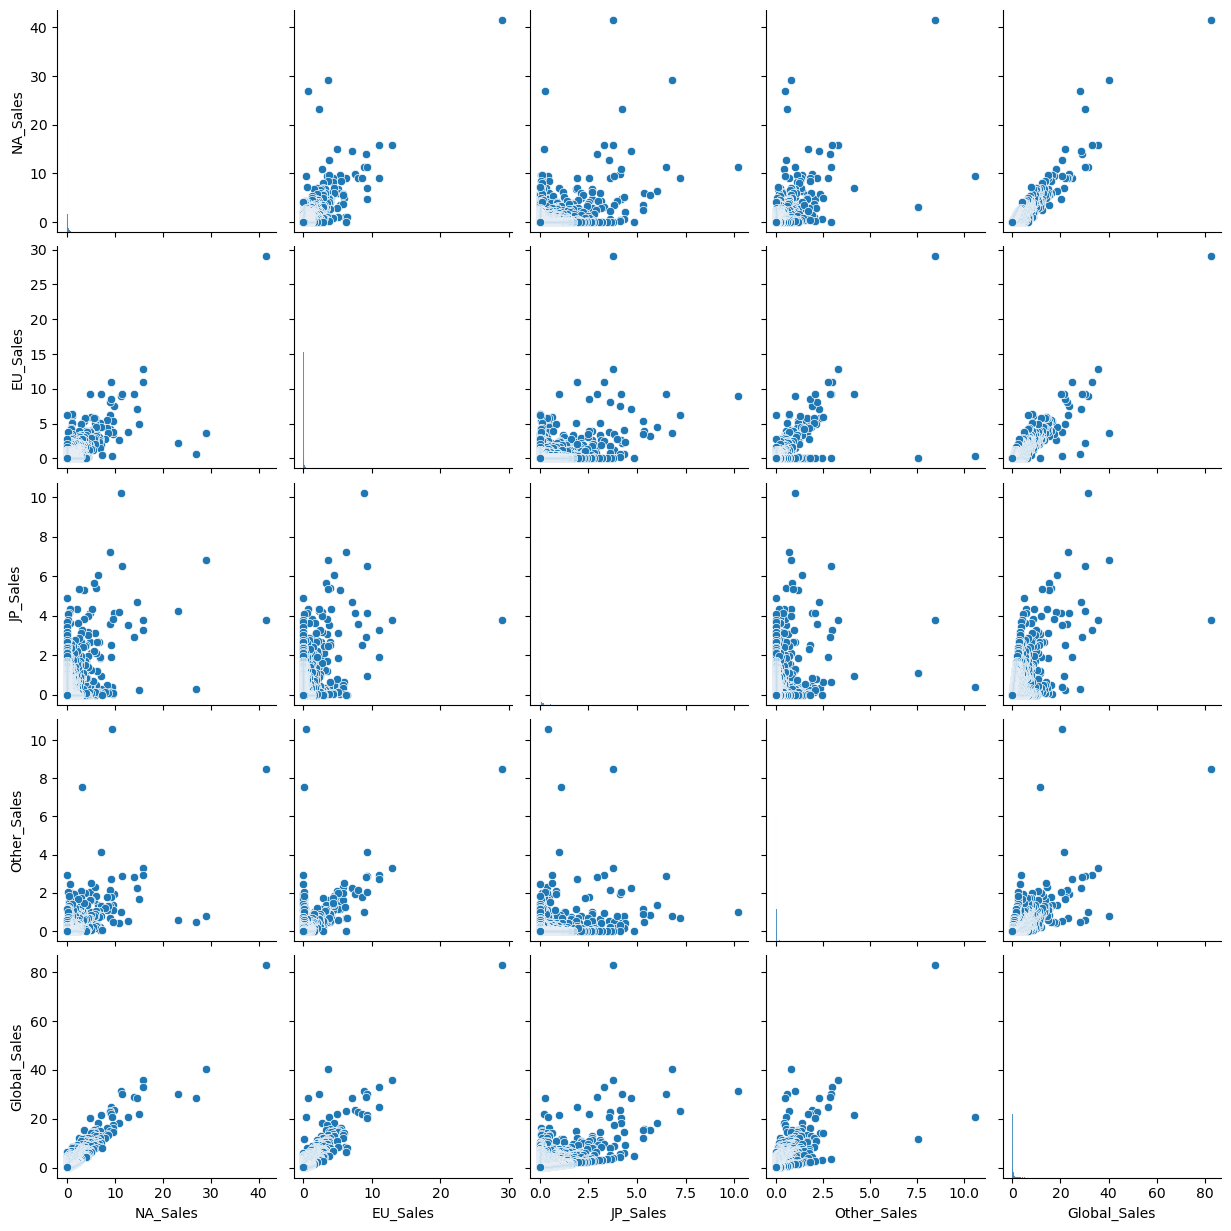

In [50]:
region_sales = df[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales','Global_Sales']]
sb.pairplot(region_sales)
plt.show()

### Can we identify any regional preferences or trends in gaming preferences?

In [35]:
genre_sales = df.groupby('Genre')[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales','Global_Sales']].sum()

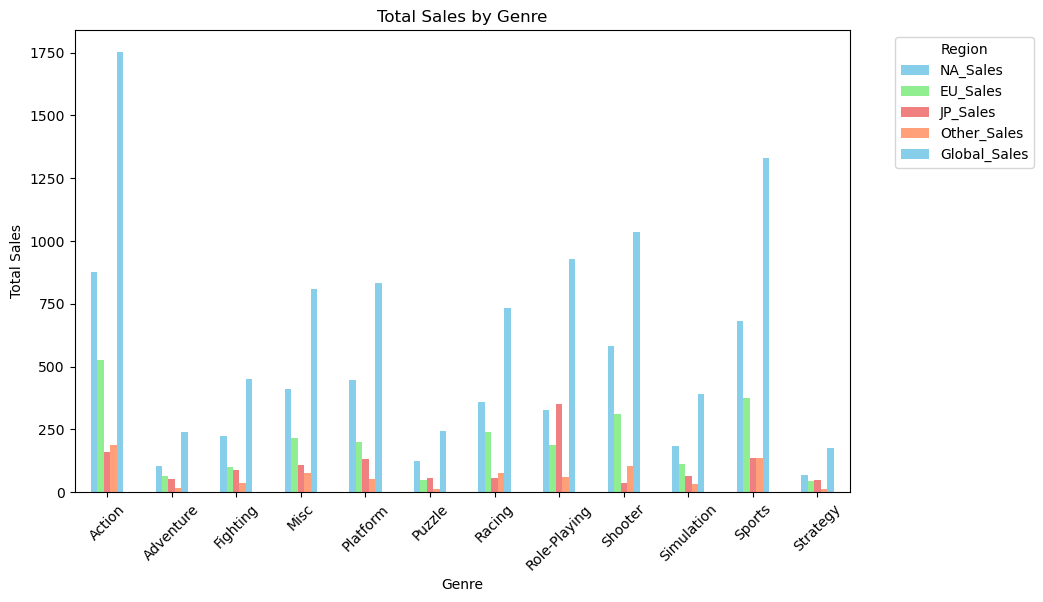

In [37]:
genre_sales.plot(kind='bar', figsize=(10, 6),color=['skyblue', 'lightgreen', 'lightcoral', 'lightsalmon'])
plt.title('Total Sales by Genre')
plt.xlabel('Genre')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.legend(title='Region',bbox_to_anchor=(1.05,1))
plt.show()

## Distribution of Sales:

### What is the distribution of sales revenue across different regions (e.g., North America, Europe, Japan, Other) for the top-selling games?

In [41]:
print(region_sales.columns.tolist())
dsr = input("Enter column Name")
dt = genre_sales.nlargest(10,dsr)
dt

['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
Enter column NameEU_Sales


,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
Genre,,,,,
Action,877.83,525.00,159.95,187.38,1751.18
Sports,683.35,376.85,135.37,134.97,1330.93
Shooter,582.60,313.27,38.28,102.69,1037.37
Racing,359.42,238.39,56.69,77.27,732.04
Misc,410.24,215.98,107.76,75.32,809.96
Platform,447.05,201.63,130.77,51.59,831.37
Role-Playing,327.28,188.06,352.31,59.61,927.37
Simulation,183.31,113.38,63.70,31.52,392.20
Fighting,223.59,101.32,87.35,36.68,448.91
